In [1]:
# # 06 - Hybrid model: alpha, switching and RRF variant
# `Score(u, i) = alpha * CB(u, i) + (1 - alpha) * CF(u, i)` with min-max normalised scores.
# 1. tune the global alpha on validation; 2. tune the switching rule (alpha per history size);
# 3. evaluate on test and compare with a fixed alpha and with Reciprocal Rank Fusion.
#
# Prerequisite: the content (notebook 04) and CF (notebook 05) hyperparameters are in `config.yaml`.

# %%
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from uniguide.config import get_path, load_config
from uniguide.data.stats import save_fig
from uniguide.evaluation.experiments import (
    evaluate_models, select_alpha_schedule, select_best_alpha)
from uniguide.pipeline import build_content_model, build_cf, build_hybrid

cfg = load_config()
SEED = cfg["seed"]
K_VALUES = tuple(cfg["evaluation"]["k_values"])
p = get_path("processed")
tables = get_path("results") / "tables"
tables.mkdir(parents=True, exist_ok=True)

train, val, test = (pd.read_parquet(p / f"{n}.parquet") for n in ["train", "val", "test"])
courses = pd.read_parquet(p / "courses.parquet")
cold_courses = set(json.loads((p / "cold_courses.json").read_text()))
courses_warm = courses[~courses["course_id"].isin(cold_courses)].reset_index(drop=True)
cold_users = json.loads((p / "cold_users.json").read_text())
train_val = pd.concat([train, val], ignore_index=True)

rng = np.random.default_rng(SEED)
val_users = val["user_id"].unique()
sample = rng.choice(val_users, size=min(3000, len(val_users)), replace=False)
val_sample = val[val["user_id"].isin(sample)]

best alpha: 0.9


,alpha,ndcg@10
0,0.0,0.038214
1,0.1,0.058694
2,0.2,0.059756
3,0.3,0.061575
4,0.4,0.066445
5,0.5,0.077112
6,0.6,0.089919
7,0.7,0.098673
8,0.8,0.104887
9,0.9,0.108181


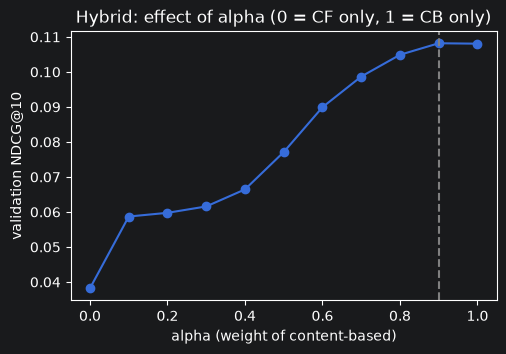

In [2]:
# ## 1. Global alpha (validation NDCG@10)
# alpha only changes how the two normalised scores are mixed, so the components are fitted once.

# %%
cb, cf = build_content_model(), build_cf()
best_alpha, alpha_table = select_best_alpha(cb, cf, train, courses_warm, val_sample, k=10)
alpha_table.to_csv(tables / "tuning_alpha.csv", index=False)
print("best alpha:", best_alpha)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(alpha_table["alpha"], alpha_table["ndcg@10"], marker="o")
ax.axvline(best_alpha, ls="--", c="grey")
ax.set(xlabel="alpha (weight of content-based)", ylabel="validation NDCG@10",
       title="Hybrid: effect of alpha (0 = CF only, 1 = CB only)")
save_fig(fig, "hybrid_alpha")
alpha_table

In [3]:
# ## 2. Switching rule (alpha per history size)
# Cold-start groups of the split (1, 3, 5 training interactions) are used to pick one alpha per size.
# With 0 interactions the hybrid returns the popularity ranking. Beyond the largest group the global alpha applies.
# Groups are small: look at the table before trusting a single best value.

# %%
schedule, schedule_table = select_alpha_schedule(
    cb, cf, train, courses_warm, val, cold_users, default_alpha=best_alpha, k=10)
schedule_table.to_csv(tables / "tuning_alpha_schedule.csv", index=False)
print("alpha_schedule:", schedule)
schedule_table.pivot(index="history", columns="alpha", values="ndcg@10").round(3)

# %%
print("Copy into config.yaml -> model:")
print(f"  alpha: {best_alpha}")
print(f"  alpha_schedule: {[list(rule) for rule in schedule]}")

alpha_schedule: [(1, 0.8), (3, 0.9), (5, 0.9)]
Copy into config.yaml -> model:
  alpha: 0.9
  alpha_schedule: [[1, 0.8], [3, 0.9], [5, 0.9]]


In [4]:
# ## 3. Test evaluation (fit on train + validation)
# Compared on the same users: hybrid with switching (official), fixed alpha, and RRF.

# %%
overrides = {"alpha": best_alpha, "alpha_schedule": schedule}
models = {
    "hybrid": build_hybrid(**overrides),
    "hybrid_fixed_alpha": build_hybrid(alpha=best_alpha, alpha_schedule=[]),
    "hybrid_rrf": build_hybrid(rrf=True),
}
for model in models.values():
    model.fit(train_val, courses_warm)

per_user = evaluate_models(models, test, K_VALUES, experiment="main", seed=SEED, per_user=True)
for name in ["hybrid", "hybrid_rrf"]:
    per_user[per_user["method"] == name].to_csv(tables / f"eval_{name}.csv", index=False)

summary = per_user.groupby(["method", "k", "metric"])["value"].mean().unstack("metric").round(4)
summary.to_csv(tables / "exp_hybrid_variants.csv")
summary

metric                 hit_rate    ndcg  precision  recall
method             k                                      
hybrid             5     0.1494  0.0827     0.0311  0.1157
                   10    0.2056  0.0979     0.0218  0.1603
hybrid_fixed_alpha 5     0.1494  0.0827     0.0311  0.1157
                   10    0.2056  0.0979     0.0218  0.1603
hybrid_rrf         5     0.1006  0.0528     0.0206  0.0778
                   10    0.1710  0.0711     0.0178  0.1310